# Task 5 — inspect the actual OCSVM and rank-blend decision lines

Analysis-only EDA: reads saved unlabeled Test dataset cards, fitted models, and submission files. It fits no model, changes no prediction, and writes no new data artifact. The project's reported lecturer exception covers Task 5's unsupervised test-only workflow; the written-rule conflict remains documented in `docs/research-note-task5.md`.

A nonlinear OCSVM in 213 dimensions has no single boundary line in an arbitrary 2D or 3D projection. We can show **exact** lines in the model's one-dimensional anomaly-score space and in the two-score planes used by the actual blends. The raw-feature plane at the end is descriptive and cannot display the full model boundary.

In [1]:
from pathlib import Path
import sys, json, joblib
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "pipeline" / "save_data.py").exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.pipeline.random_seed import set_seed
SEED = set_seed()
SRC = ROOT / "src"
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata, binned_statistic_2d
from IPython.display import display

def read_test(name):
    card = json.loads((SRC / "task5/data/eda" / f"{name}.json").read_text(encoding="utf-8"))
    assert set(card["splits"]) == {"test"}
    frame = pd.read_parquet(SRC / card["splits"]["test"]["path"])
    assert frame.player_id.is_unique and "is_anomaly" not in frame
    return frame
old = read_test("eda_1_v2")
new = read_test("eda_behavior_views_v3")
assert old.player_id.equals(new.player_id)
old_X, new_X = old.drop(columns="player_id"), new.drop(columns="player_id")
def model(name):
    card = json.loads((SRC / "task5/save" / f"{name}.json").read_text(encoding="utf-8"))
    return joblib.load(SRC / card["model_path"])
ocsvm = model("t5_r4_ocsvm_nu10_alert25_v4")
gmm = model("t5_r2_gmm_engineered_v2")
peer = model("t5_peer_change_v3")
bot = model("t5_bot_regular_v3")
files = {
    "OCSVM": "kaggle_t12345_t5_alert25_v9.csv",
    "GMM": "kaggle_t12345_t5_gmm_match_v9_v11.csv",
    "v17": "kaggle_t12345_t3log_t5_rankblend25_v17.csv",
    "v18": "kaggle_t12345_t5_peerchange_v18.csv",
    "v19": "kaggle_t12345_t5_peerchange_bot_v19.csv",
}
pred = {name: pd.read_csv(SRC / "submission" / filename).task5.to_numpy(dtype=np.int8)
        for name, filename in files.items()}
assert all(len(x)==25889 and x.sum()==6531 for x in pred.values())
print("All five selections have 6,531 alerts among",len(old_X),"accounts")

All five selections have 6,531 alerts among 25889 accounts


In [2]:
score_o = np.asarray(ocsvm.anomaly_score(old_X),dtype=float)
score_g = np.asarray(gmm.anomaly_score(old_X),dtype=float)
score_p = np.asarray(peer.anomaly_score(new_X),dtype=float)
score_b = np.asarray(bot.anomaly_score(new_X),dtype=float)
assert all(np.isfinite(x).all() for x in [score_o,score_g,score_p,score_b])
assert np.array_equal((score_o >= ocsvm.threshold_).astype(np.int8),pred["OCSVM"])
def rank(values): return rankdata(values,method="average")/len(values)
ro, rg, rp, rb = [rank(x) for x in [score_o,score_g,score_p,score_b]]
v17_score=.5*ro+.5*rg
v18_score=.5*v17_score+.5*rp
v19_score=.8*v18_score+.2*rb
N_ALERTS=6531
def top_k(score):
    selected=np.lexsort((np.arange(len(score)),-score))[:N_ALERTS]
    out=np.zeros(len(score),dtype=np.int8);out[selected]=1
    return out
for name,score in [("v17",v17_score),("v18",v18_score),("v19",v19_score)]:
    assert np.array_equal(top_k(score),pred[name]),name
print("Reproduced all three blend selections exactly")
print("OCSVM operational threshold:",round(float(ocsvm.threshold_),6))
print("Native OCSVM score=0 is not the 6,531-alert operational threshold")

Reproduced all three blend selections exactly
OCSVM operational threshold: -582.200783
Native OCSVM score=0 is not the 6,531-alert operational threshold


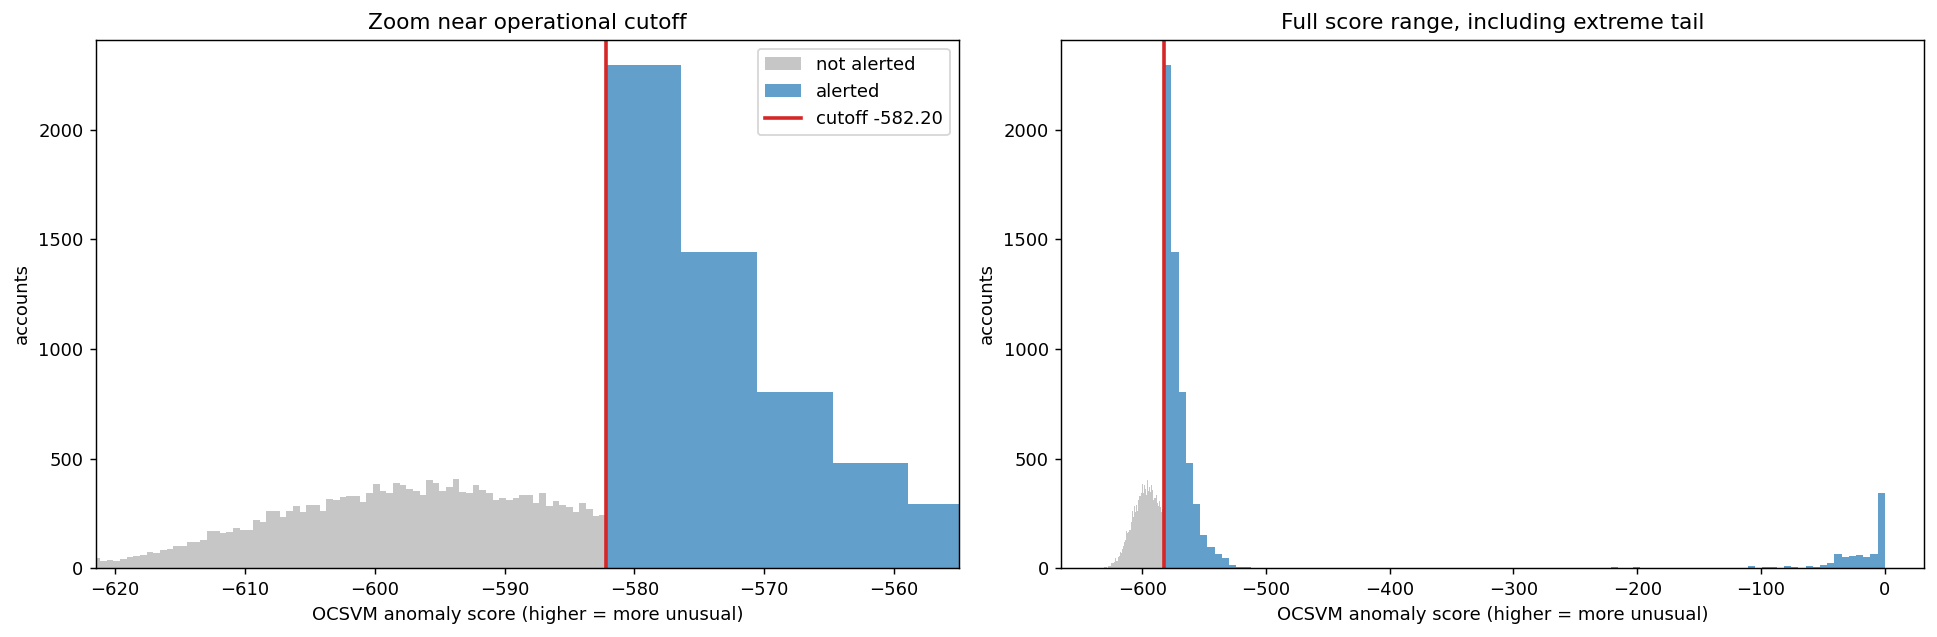

In [3]:
# Figure 1: the exact OCSVM operational decision is a vertical line in score space.
fig,axes=plt.subplots(1,2,figsize=(15,5),dpi=130)
for ax in axes:
    ax.hist(score_o[pred["OCSVM"]==0],bins=100,color="0.72",alpha=.8,label="not alerted")
    ax.hist(score_o[pred["OCSVM"]==1],bins=100,color="tab:blue",alpha=.7,label="alerted")
    ax.axvline(ocsvm.threshold_,color="tab:red",linewidth=2,label=f"cutoff {ocsvm.threshold_:.2f}")
    ax.set(xlabel="OCSVM anomaly score (higher = more unusual)",ylabel="accounts")
axes[0].set_xlim(np.quantile(score_o,.01),np.quantile(score_o,.95))
axes[0].set_title("Zoom near operational cutoff")
axes[1].set_title("Full score range, including extreme tail")
axes[0].legend()
plt.tight_layout();plt.show()

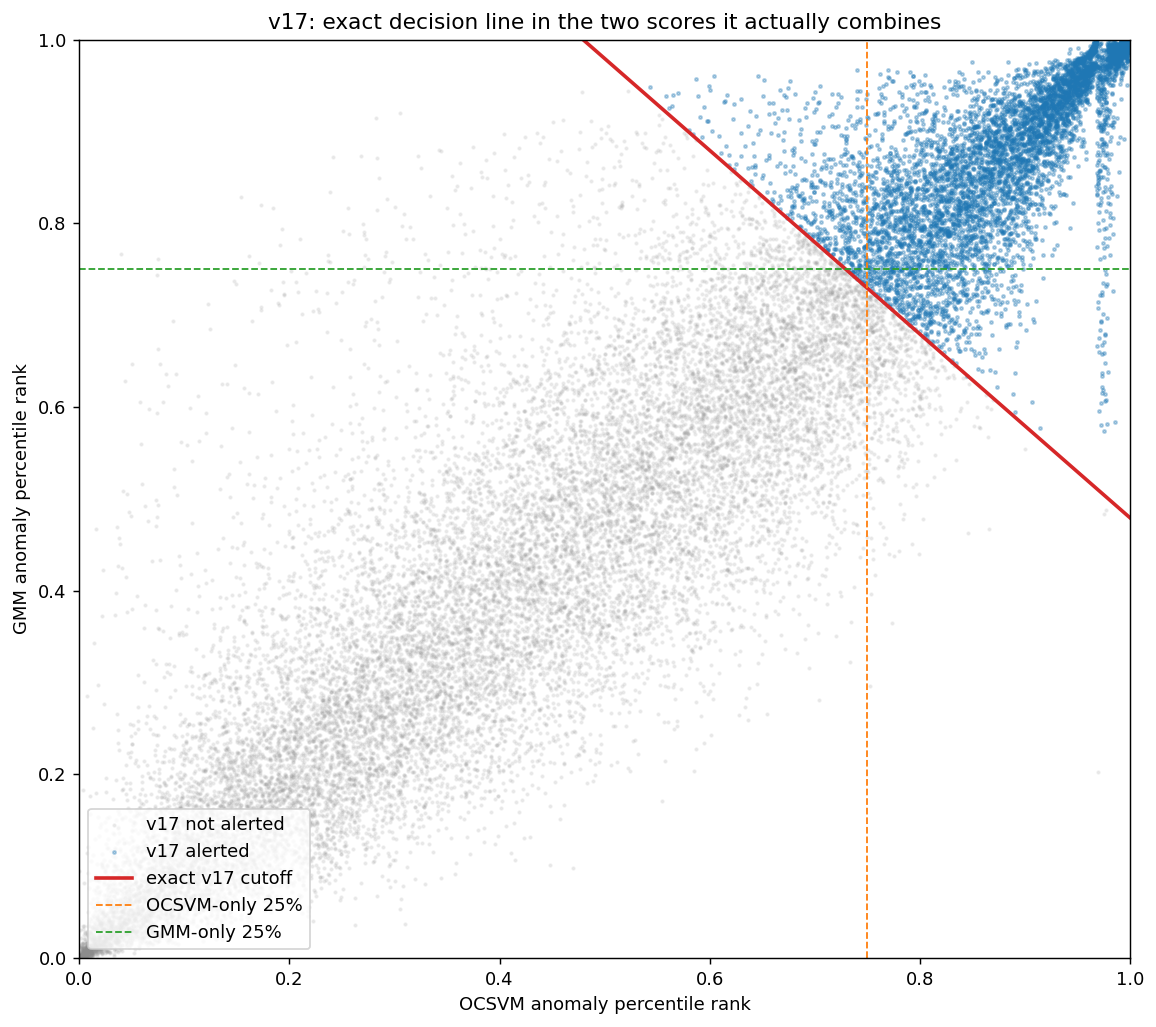

v17 rank cutoff 0.739861 ; both model rankings enter the line


In [4]:
# Figure 2: exact v17 line in OCSVM-vs-GMM percentile-rank space.
# Each model alone would use a vertical/horizontal top-6,531 cutoff; v17 averages both ranks.
def selection_cutoff(score, selection):
    low=float(score[selection==1].min());high=float(score[selection==0].max())
    assert low >= high
    return (low+high)/2
c17=selection_cutoff(v17_score,pred["v17"])
fig,ax=plt.subplots(figsize=(9,8),dpi=130)
ax.scatter(ro[pred["v17"]==0],rg[pred["v17"]==0],s=2,alpha=.12,c="0.55",rasterized=True,label="v17 not alerted")
ax.scatter(ro[pred["v17"]==1],rg[pred["v17"]==1],s=3,alpha=.32,c="tab:blue",rasterized=True,label="v17 alerted")
xline=np.linspace(0,1,500)
ax.plot(xline,2*c17-xline,color="tab:red",linewidth=2,label="exact v17 cutoff")
ax.axvline(np.quantile(ro,.75),color="tab:orange",linestyle="--",linewidth=1,label="OCSVM-only 25%")
ax.axhline(np.quantile(rg,.75),color="tab:green",linestyle="--",linewidth=1,label="GMM-only 25%")
ax.set(xlim=(0,1),ylim=(0,1),xlabel="OCSVM anomaly percentile rank",ylabel="GMM anomaly percentile rank",
       title="v17: exact decision line in the two scores it actually combines")
ax.legend(loc="lower left");plt.tight_layout();plt.show()
print("v17 rank cutoff",round(c17,6),"; both model rankings enter the line")

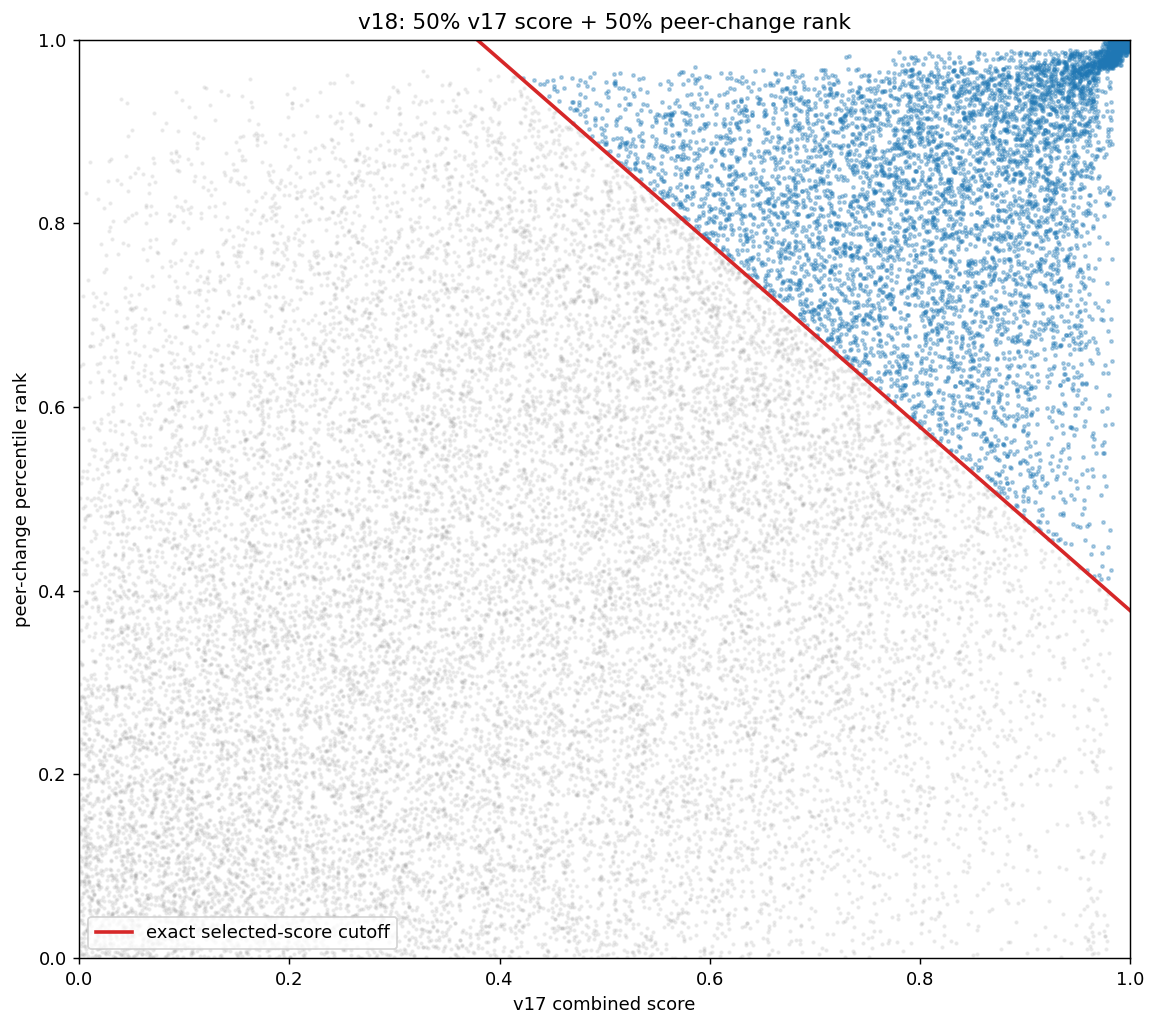

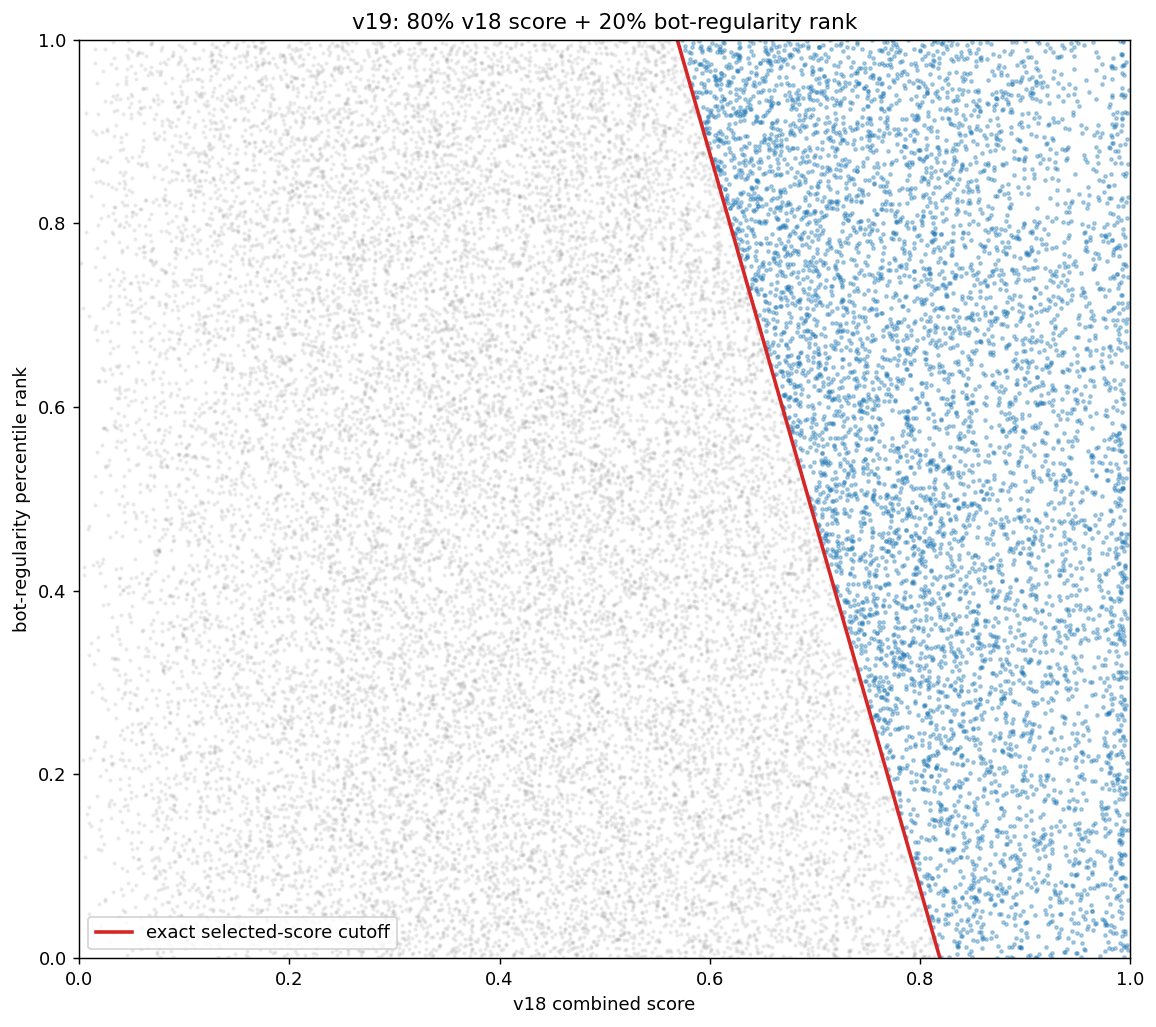

v18 cutoff 0.68939 v19 cutoff 0.655388


In [5]:
# Figures 3-4: the controlled new candidates also have exact lines in their score planes.
def decision_plane(x,y,score,selection,wx,wy,title,xlabel,ylabel):
    cutoff=selection_cutoff(score,selection)
    fig,ax=plt.subplots(figsize=(9,8),dpi=130)
    ax.scatter(x[selection==0],y[selection==0],s=2,alpha=.12,c="0.55",rasterized=True)
    ax.scatter(x[selection==1],y[selection==1],s=3,alpha=.32,c="tab:blue",rasterized=True)
    line=np.linspace(0,1,500)
    ax.plot(line,(cutoff-wx*line)/wy,color="tab:red",linewidth=2,label="exact selected-score cutoff")
    ax.set(xlim=(0,1),ylim=(0,1),xlabel=xlabel,ylabel=ylabel,title=title)
    ax.legend(loc="lower left");plt.tight_layout();plt.show()
    return cutoff
c18=decision_plane(v17_score,rp,v18_score,pred["v18"],.5,.5,
    "v18: 50% v17 score + 50% peer-change rank", "v17 combined score", "peer-change percentile rank")
c19=decision_plane(v18_score,rb,v19_score,pred["v19"],.8,.2,
    "v19: 80% v18 score + 20% bot-regularity rank", "v18 combined score", "bot-regularity percentile rank")
print("v18 cutoff",round(c18,6),"v19 cutoff",round(c19,6))

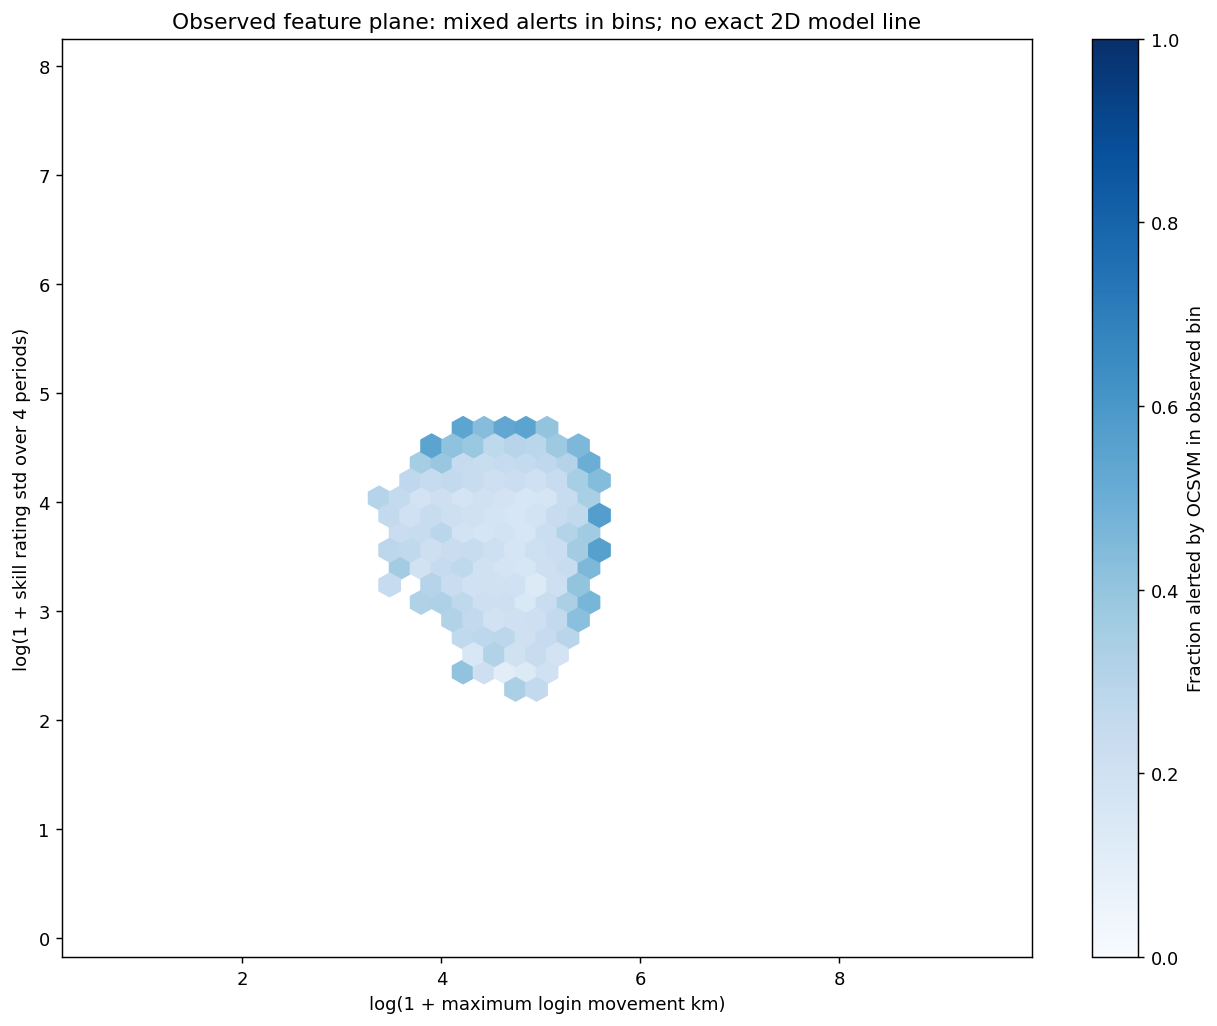

The exact OCSVM cutoff is in score space. This feature plane averages over the remaining 211 inputs.


In [6]:
# Figure 5: observed raw-feature plane. This is intentionally NOT called a model boundary.
# Two dominant OCSVM/PCA-related dimensions are shown; other 211 model inputs still affect each dot.
x=np.log1p(old_X["login_move_max_km"].fillna(old_X["login_move_max_km"].median()).clip(lower=0))
y=np.log1p(old_X["skill_rating_std4"].fillna(old_X["skill_rating_std4"].median()).clip(lower=0))
fig,ax=plt.subplots(figsize=(10,8),dpi=130)
ax.hexbin(x,y,C=pred["OCSVM"],reduce_C_function=np.mean,gridsize=42,mincnt=20,cmap="Blues",vmin=0,vmax=1)
bar=fig.colorbar(ax.collections[0],ax=ax)
bar.set_label("Fraction alerted by OCSVM in observed bin")
ax.set(xlabel="log(1 + maximum login movement km)",ylabel="log(1 + skill rating std over 4 periods)",
       title="Observed feature plane: mixed alerts in bins; no exact 2D model line")
plt.tight_layout();plt.show()
print("The exact OCSVM cutoff is in score space. This feature plane averages over the remaining 211 inputs.")

## What these views establish

- The saved OCSVM 25%-alert decision is exactly `anomaly_score >= threshold_`; the threshold is visible as a vertical line in Figure 1. The native One-Class SVM boundary at its own zero decision function is a different rule from the operational alert budget. `nu=0.10` is not a 10% alert fraction.
- v17's **exact** line lives in the plane of OCSVM and GMM percentile ranks because the submission averages those ranks. Likewise v18/v19 have exact lines in their *component-score* planes. These lines explain the actual selection rules without projecting away the quantities used for the decisions.
- The selected model still uses 213 old EDA predictors. Figure 5 shows why no raw two-feature line can explain every alert: accounts with similar movement and skill variability can receive different scores from the other features. The bin color is descriptive alert frequency, not F3 or a probability of threat.
- A separate 3D PCA audit of the union of 252 old/new predictors found that three components retain **12.93%** of variance after median imputation, robust scaling, and clipping at ±5 scaled units. Without clipping they retain **76.70%**, largely driven by movement and skill-rating extremes. Neither projection gives a faithful 3D OCSVM boundary. These score-space plots are the more faithful view of the actual decisions.

## Follow one player ID across five score views

The feature/PCA embedding fixes each account's coordinates, so it cannot show rank movement. This view fixes X = OCSVM percentile rank and Y = GMM percentile rank, then places the **current version percentile rank** on Z. The slider changes OCSVM → GMM → v17 → v18 → v19. Every account has the **same marker size and opacity**, regardless of alert status. Its blue shade is assigned once from its **frozen v17 combined score**: light blue near the low/low corner, dark blue near the high/high corner. That shade stays with `player_id` across all frames; hover shows the exact ID and alert status. The red line on the floor is the exact v17 OCSVM/GMM rank boundary, kept as a reference. One highlighted ID's five-step path is drawn separately. Change `FOCUS_PLAYER_ID` and rerun the cell to trace another account. The shared sample includes random accounts and large rank movers, so it is not representative of alert prevalence.

In [7]:
import plotly.graph_objects as go

# Freeze each player_id to its v17 combined score on the OCSVM/GMM plane.
ids = old.player_id.astype(str).to_numpy()
id_color = v17_score.copy()
version_rank = {
    "OCSVM": ro,
    "GMM": rg,
    "v17": rank(v17_score),
    "v18": rank(v18_score),
    "v19": rank(v19_score),
}
version_alert = {
    "OCSVM": pred["OCSVM"], "GMM": pred["GMM"],
    "v17": pred["v17"], "v18": pred["v18"], "v19": pred["v19"],
}
versions = list(version_rank)
rng = np.random.default_rng(SEED)
random_rows = rng.choice(len(ids), size=1000, replace=False)
movers_18 = np.argsort(np.abs(version_rank["v18"] - version_rank["v17"]))[-400:]
movers_19 = np.argsort(np.abs(version_rank["v19"] - version_rank["v18"]))[-400:]
sample_rows = np.unique(np.r_[random_rows, movers_18, movers_19])
changed = np.flatnonzero(pred["v17"] != pred["v19"])
default_focus = changed[np.argmax(np.abs(version_rank["v19"][changed] - version_rank["v17"][changed]))]
FOCUS_PLAYER_ID = None  # Set to one value from old.player_id, then rerun this cell.
focus_row = default_focus if FOCUS_PLAYER_ID is None else int(np.flatnonzero(ids == str(FOCUS_PLAYER_ID))[0])
sample_rows = np.unique(np.r_[sample_rows, focus_row])

def account_trace(version):
    selection = version_alert[version][sample_rows]
    hover = [f"player_id: {ids[i]}<br>{version} rank: {version_rank[version][i]:.3f}<br>" +
             ("alert" if selection[j] else "not alert") for j, i in enumerate(sample_rows)]
    return go.Scatter3d(
        x=ro[sample_rows], y=rg[sample_rows], z=version_rank[version][sample_rows],
        mode="markers", name="Accounts",
        marker=dict(size=5.0, color=id_color[sample_rows],
                    colorscale=[[0,"rgb(125,181,219)"],[1,"rgb(8,48,107)"]],
                    cmin=0, cmax=1, opacity=.86,
                    colorbar=dict(title="Frozen v17 rank", thickness=12)),
        text=hover, hovertemplate="%{text}<extra></extra>", showlegend=False,
    )

focus_z = [float(version_rank[name][focus_row]) for name in versions]
focus_trace = go.Scatter3d(
    x=[ro[focus_row]]*5, y=[rg[focus_row]]*5, z=focus_z,
    mode="lines+markers+text", name=f"Focus: {ids[focus_row]}",
    text=versions, textposition="top center",
    line=dict(color="midnightblue", width=6), marker=dict(color="midnightblue", size=7),
    hovertemplate="%{text}<br>rank %{z:.3f}<extra>focused ID</extra>",
)
# The exact v17 score boundary is ro + rg = 2*c17 in the OCSVM/GMM floor plane.
boundary_x = np.linspace(max(0, 2*c17-1), min(1, 2*c17), 200)
boundary_trace = go.Scatter3d(
    x=boundary_x, y=2*c17-boundary_x, z=np.full_like(boundary_x, .025),
    mode="lines", name="v17 boundary", line=dict(color="red", width=7),
    hovertemplate="v17 OCSVM/GMM cutoff<extra></extra>",
)
fig = go.Figure(data=[account_trace("OCSVM"), focus_trace, boundary_trace])
fig.frames = [go.Frame(name=name, data=[account_trace(name)], traces=[0]) for name in versions]
fig.update_layout(
    title=f"Frozen v17 color, moving rank · focus {ids[focus_row]}",
    width=1000, height=760, margin=dict(l=0,r=0,t=55,b=0),
    scene=dict(xaxis=dict(title="OCSVM rank",range=[0,1]),
               yaxis=dict(title="GMM rank",range=[0,1]),
               zaxis=dict(title="Current version rank",range=[0,1]),
               aspectmode="cube", uirevision="stable-camera"),
    sliders=[dict(active=0, currentvalue=dict(prefix="Version: "),
                  steps=[dict(label=name, method="animate",
                              args=[[name],dict(frame=dict(duration=450,redraw=True),
                                                transition=dict(duration=0),mode="immediate")])
                         for name in versions])],
    updatemenus=[dict(type="buttons", showactive=False, x=.01, y=0,
                      buttons=[dict(label="Play", method="animate",
                                    args=[None,dict(frame=dict(duration=700,redraw=True),
                                                   transition=dict(duration=0),fromcurrent=True)])])],
)
fig.show()
print("Shared accounts shown:",len(sample_rows),"of",len(ids),"; focused ID:",ids[focus_row])
print("Focus ranks:",{name:round(float(version_rank[name][focus_row]),4) for name in versions})
print("Blue shade is frozen from v17 score; every account marker has the same size. Red floor line is the v17 boundary. This sample oversamples large movers.")

Shared accounts shown: 1742 of 25889 ; focused ID: P011168
Focus ranks: {'OCSVM': 0.9163, 'GMM': 0.9279, 'v17': 0.9286, 'v18': 0.4644, 'v19': 0.3113}
Blue shade is frozen from v17 score; every account marker has the same size. Red floor line is the v17 boundary. This sample oversamples large movers.
